In [3]:
import os
from osgeo import gdal
import sys
sys.path.append('/Users/chanagan/Documents/GitHub/ImageryResources/Functions/')
import TiffTools as tt

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy import signal, ndimage
import rioxarray

from pyproj import Proj, Geod
import pygmt

%load_ext autoreload
%autoreload 2

## Copernicuss S2

In [ ]:
gdalwarp -t_srs EPSG:32619 -overwrite -cutline /Users/chanagan/Downloads/Venezuela2026Doublet/GIS/venezuela_aoi_forJD.geojson \
          -tr 10 -10 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
            T19PEM_20260625T150719_B04_10m.jp2 T19PFM_20260625T150719a_B04_10m.jp2 Post_T19PFM_20260625T150719a_B04_10m.tif
gdalwarp -t_srs EPSG:32619 -overwrite -cutline /Users/chanagan/Downloads/Venezuela2026Doublet/GIS/venezuela_aoi_forJD.geojson \
          -tr 10 -10 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          T19PEM_20260506T150719a_B04_10m.jp2 T19PFM_20260506T150719_B04_10m.jp2 Pre_T19PEM_20260506T150719_B04_10m.tif

mm3d Mm2dPosSism Pre_T19PEM_20260506T150719_B04_10m.tif Post_T19PFM_20260625T150719a_B04_10m.tif  SsResolOpt=1 CorMin=0.1 Dequant=false DirMEC='MEC_S2_COP/'  

In [6]:
tt.micmacPostProcessing(folder=f'/Users/chanagan/Downloads/Venezuela2026Doublet/S2A_Copernicus/B04/MEC_S2_COP/',
                             prefiles=[f'/Users/chanagan/Downloads/Venezuela2026Doublet/S2A_Copernicus/B04/Post_T19PFM_20260625T150719a_B04_10m.tif',
                                       '/Users/chanagan/Downloads/Venezuela2026Doublet/S2A_Copernicus/B04/Pre_T19PEM_20260506T150719_B04_10m.tif'],
                             outprefix=f'/Users/chanagan/Downloads/Venezuela2026Doublet/S2A_Copernicus/B04/MEC_S2_COP/')



Nodata value for mask: -9999.0
Setting nodata value to -9999
Saving /Users/chanagan/Downloads/Venezuela2026Doublet/S2A_Copernicus/B04/MEC_S2_COP/NSmicmac.tif
Saving /Users/chanagan/Downloads/Venezuela2026Doublet/S2A_Copernicus/B04/MEC_S2_COP/EWmicmac.tif
Saving /Users/chanagan/Downloads/Venezuela2026Doublet/S2A_Copernicus/B04/MEC_S2_COP/Correlmicmac.tif


### Spot check 

Eastern most peninsula deformation

In [ ]:
gdalwarp -t_srs EPSG:32619 -overwrite -cutline /Volumes/Venezuela/Venezuela2026Doublet/GIS/venezuela_aoi_eastern_spotcheck.shp.geojson \
          -tr 10 -10 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
            T19PGM_20260622T145719_B04_10m.jp2 PreEastSpot_T19PGM_20260622T145719_B04_10m.tif
gdalwarp -t_srs EPSG:32619 -overwrite -cutline /Volumes/Venezuela/Venezuela2026Doublet/GIS/venezuela_aoi_eastern_spotcheck.shp.geojson \
          -tr 10 -10 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          T19PGM_20260627T145721_B04_10m.jp2 PostEastSpot_T19PGM_20260627T145721_B04_10m.tif

mm3d Mm2dPosSism PreEastSpot_T19PGM_20260622T145719_B04_10m.tif PostEastSpot_T19PGM_20260627T145721_B04_10m.tif  SsResolOpt=1 CorMin=0.1 Dequant=false DirMEC='MEC_S2_COP_EastSpot/'  

## GEE S2

In [16]:
gdalwarp -t_srs EPSG:32619 -overwrite -cutline /Users/chanagan/Downloads/Venezuela2026Doublet/GIS/venezuela_aoi_forJD.geojson \
          -tr 10 -10 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
            sentinel2_band4_2026-06-24_2026-06-29-0000000000-0000000000.tif POSTsentinel2_band4_2026-06-24_2026-06-29-0000000000-0000000000.tif
gdalwarp -t_srs EPSG:32619 -overwrite -cutline /Users/chanagan/Downloads/Venezuela2026Doublet/GIS/venezuela_aoi_forJD.geojson \
          -tr 10 -10 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          sentinel2_band4_2026-05-05_2026-05-09-0000000000-0000000000.tif PREsentinel2_band4_2026-05-05_2026-05-09-0000000000-0000000000.tif

#/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/sentinel2_band4_2026-05-05_2026-05-09-0000000000-0000000000.tif /Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/sentinel2_band4_2026-06-24_2026-06-29-0000000000-0000000000.tif



SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (1471839537.py, line 3)

### Mask by cloud brightness

In [ ]:
# Cloud and water mask

import numpy as np
from scipy.ndimage import binary_dilation
import rasterio


def mask_bright_objects(
    arr,
    percentile=99,
    buffer_pixels=4,
    nodata=-9999
):
    """
    Mask bright objects (e.g., clouds) using a brightness threshold.

    Parameters
    ----------
    arr : ndarray
        Single-band image.
    percentile : float
        Brightness percentile above which pixels are masked.
    buffer_pixels : int
        Buffer around masked pixels.
    nodata : float
        Value used for masking.

    Returns
    -------
    masked : ndarray
    mask : ndarray(bool)
    """

    masked = arr.astype(float).copy()

    valid = np.isfinite(masked)

    thresh = np.percentile(masked[valid], percentile)

    mask = masked >= thresh

    mask = binary_dilation(mask, iterations=buffer_pixels)

    masked[mask] = nodata

    return masked, mask

import numpy as np
import geopandas as gpd
from rasterio.features import rasterize
from scipy.ndimage import binary_dilation, binary_erosion


def mask_ocean(
    arr,
    transform,
    crs,
    landmask_file,
    nodata=np.nan,
    coastline_buffer=0,
    all_touched=False,
):
    """
    Mask ocean using a GSHHG land polygon shapefile.

    Parameters
    ----------
    arr : ndarray
        2D raster.
    transform : affine.Affine
        Raster transform.
    crs : rasterio.crs.CRS
        Raster CRS.
    landmask_file : str
        Path to GSHHG land shapefile
        (e.g. GSHHS_f_L1.shp).
    nodata : float
        Output nodata value.
    coastline_buffer : int
        Buffer (pixels).

        >0 : remove pixels near coastline (recommended)
        <0 : expand land into ocean
         0 : no buffering
    all_touched : bool
        Passed to rasterize(). False is usually best.

    Returns
    -------
    masked : ndarray
    landmask : ndarray(bool)
    """

    # Read GSHHG polygons
    gdf = gpd.read_file(landmask_file)

    # Repair invalid geometries
    gdf["geometry"] = gdf.geometry.buffer(0)

    # Match raster CRS
    if gdf.crs != crs:
        print('Projecting to',crs)
        gdf = gdf.to_crs(crs)

        gdf = gdf[gdf.geometry.bounds.apply(
                    lambda row: np.isfinite(row).all(),
                    axis=1)]

    # Rasterize land polygons
    landmask = rasterize(
        ((geom, 1) for geom in gdf.geometry),
        out_shape=arr.shape,
        transform=transform,
        fill=0,
        all_touched=all_touched,
        dtype=np.uint8,
    ).astype(bool)

    # Optional coastline buffer
    if coastline_buffer > 0:
        landmask = binary_erosion(
            landmask,
            iterations=coastline_buffer,
        )

    elif coastline_buffer < 0:
        landmask = binary_dilation(
            landmask,
            iterations=abs(coastline_buffer),
        )

    # Apply mask
    masked = arr.astype(float).copy()
    masked[~landmask] = nodata

    return masked, landmask


files = ['/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/POSTsentinel2_band4_2026-06-24_2026-06-29-0000000000-0000000000.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/PREsentinel2_band4_2026-05-05_2026-05-09-0000000000-0000000000.tif']
landmask_file = '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/gshhg-shp-2.3.7/GSHHS_shp/f/GSHHS_f_L1_epsg32619.shp'

for file in files:
    with rasterio.open(file) as src:
        arr = src.read(1)
        profile = src.profile
        nodata = src.nodata
        transform = src.transform
        crs = src.crs

        masked, _ = mask_ocean(arr,transform,crs,landmask_file,
                nodata=-9999,coastline_buffer=5)
        
        buffered, _ = mask_bright_objects(masked, percentile=95, buffer_pixels=4)

        with rasterio.open(f"{file[:-4]}_masked.tif", "w", **profile) as dst:
            dst.write(buffered, 1)

In [46]:
tt.micmacPostProcessing(folder=f'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/',
                             prefiles=[f'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/PREsentinel2_band4_2026-05-05_2026-05-09-0000000000-0000000000_masked.tif',
                                       '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/POSTsentinel2_band4_2026-06-24_2026-06-29-0000000000-0000000000_masked.tif'],
                             outprefix=f'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/')

Nodata value for mask: -9999.0
Setting nodata value to -9999
Saving /Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/NSmicmac.tif
Saving /Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/EWmicmac.tif
Saving /Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/Correlmicmac.tif


### Mask by correlation score

In [47]:
tt.micmacPostProcessing(folder=f'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/',
                             prefiles=[f'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/PREsentinel2_band4_2026-05-05_2026-05-09-0000000000-0000000000.tif',
                                       '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/POSTsentinel2_band4_2026-06-24_2026-06-29-0000000000-0000000000.tif'],
                             outprefix=f'/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/nomask')

Nodata value for mask: -9999.0
Setting nodata value to -9999
Saving /Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/nomaskNSmicmac.tif
Saving /Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/nomaskEWmicmac.tif
Saving /Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/nomaskCorrelmicmac.tif


In [51]:
corrf = '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/nomaskCorrelmicmac.tif' 
with rasterio.open(corrf) as src:
        arr = src.read(1)
        mask = (arr < 0.2)

files = ['/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/nomaskEWmicmac.tif', 
        '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/nomaskNSmicmac.tif']

for file in files:
    with rasterio.open(file) as src:
        arr = src.read(1)
        profile = src.profile
        nodata = src.nodata
        transform = src.transform
        crs = src.crs

        masked, _ = mask_ocean(arr,transform,crs,landmask_file,
                nodata=nodata,coastline_buffer=5)

        # Correlation mask 
        masked[mask] = nodata

        with rasterio.open(f"{file[:-4]}_masked.tif", "w", **profile) as dst:
            dst.write(masked, 1)

In [ ]:
95

### curl with S2

In [6]:
files = ['/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/S2_20260505_20260629_EW_masked.tif', 
         '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/S2_02260505_20260629_NS_masked.tif']

with rasterio.open(files[1]) as src:
    ns = src.read(1)
    profile = src.profile
    nodata = src.nodata
with rasterio.open(files[1]) as src:
    ew = src.read(1)

curl = tt.curl_2d(ew,ns)

with rasterio.open('/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/MEC_S2_GEE/S2_02260505_20260629_curl.tif', "w", **profile) as dst:
    dst.write(curl, 1)

## GEE with S1A

In [8]:
gdalwarp -t_srs EPSG:32619 -overwrite -cutline /Users/chanagan/Downloads/Venezuela2026Doublet/GIS/venezuela_aoi_forJD.geojson \
          -tr 10 -10 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          sentinel1_VV_2026-06-24_2026-06-26-0000000000-0000000000.tif sentinel1_VV_2026-06-24_2026-06-26-0000000000-0000000000_nodata.tif

gdalwarp -t_srs EPSG:32619 -overwrite -cutline /Users/chanagan/Downloads/Venezuela2026Doublet/GIS/venezuela_aoi_forJD.geojson \
          -tr 10 -10 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          sentinel1_VV_2026-06-13_2026-06-19-0000000000-0000000000.tif sentinel1_VV_2026-06-13_2026-06-19-0000000000-0000000000_nodata.tif

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (1158819756.py, line 3)

In [ ]:
mm3d Mm2dPosSism sentinel1_VV_2026-06-13_2026-06-19-0000000000-0000000000.tif  sentinel1_VV_2026-06-24_2026-06-26-0000000000-0000000000.tif SsResolOpt=1 CorMin=0.1 Dequant=false DirMEC='MEC_S1A_GEE/'  


In [9]:
tt.micmacPostProcessing(folder=f'/Users/chanagan/Downloads/Venezuela2026Doublet/S1_GRD_GEE/MEC_S1A_GEE/',
                             prefiles=[f'/Users/chanagan/Downloads/Venezuela2026Doublet/S1_GRD_GEE/sentinel1_VV_2026-06-24_2026-06-26-0000000000-0000000000_nodata.tif',
                                       f'/Users/chanagan/Downloads/Venezuela2026Doublet/S1_GRD_GEE/sentinel1_VV_2026-06-13_2026-06-19-0000000000-0000000000_nodata.tif'],
                             outprefix=f'/Users/chanagan/Downloads/Venezuela2026Doublet/S1_GRD_GEE/MEC_S1A_GEE/')


Nodata value for mask: -9999.0
Setting nodata value to -9999
Saving /Users/chanagan/Downloads/Venezuela2026Doublet/S1_GRD_GEE/MEC_S1A_GEE/NSmicmac.tif
Saving /Users/chanagan/Downloads/Venezuela2026Doublet/S1_GRD_GEE/MEC_S1A_GEE/EWmicmac.tif
Saving /Users/chanagan/Downloads/Venezuela2026Doublet/S1_GRD_GEE/MEC_S1A_GEE/Correlmicmac.tif


In [ ]:
/Users/chanagan/Downloads/Venezuela2026Doublet/S1_GRD_GEE/MEC_S1A_GEE/EWmicmac.tif 
/Users/chanagan/Downloads/Venezuela2026Doublet/S1_GRD_GEE/MEC_S1A_GEE/NSmicmac.tif

old

## Metashape with worldview

In [10]:
import numpy as np
from scipy.ndimage import binary_dilation
import numpy as np
import geopandas as gpd
from rasterio.features import rasterize
from scipy.ndimage import binary_dilation, binary_erosion


def buffer_nodata(arr, nodata=-9999, buffer_pixels=1, connectivity=2):
    """
    Expand (buffer) NoData regions by a specified number of pixels.

    Parameters
    ----------
    arr : ndarray
        Input raster.
    nodata : float or int, optional
        NoData value. If np.nan, NaNs are treated as NoData.
    buffer_pixels : int, optional
        Number of pixels to buffer.
    connectivity : int, optional
        1 = 4-connected neighbors
        2 = 8-connected neighbors (default)

    Returns
    -------
    buffered : ndarray
        Raster with buffered NoData regions.
    """

    buffered = arr.copy()

    # Build nodata mask
    if np.isnan(nodata):
        mask = np.isnan(arr)
    else:
        mask = arr == nodata

    # Structuring element
    if connectivity == 1:
        structure = np.array([[0,1,0],
                              [1,1,1],
                              [0,1,0]], dtype=bool)
    else:
        structure = np.ones((3,3), dtype=bool)

    # Expand the mask
    expanded = binary_dilation(
        mask,
        structure=structure,
        iterations=buffer_pixels
    )

    # Set expanded pixels to nodata
    if np.isnan(nodata):
        buffered[expanded] = np.nan
    else:
        buffered[expanded] = nodata

    return buffered 

def rotate_stripe_remove(data, cutoff, fs, order=4, angle=0, nodata=np.nan):
    """
    Rotate data so stripes are horizontal, average signal along rows, 
    low pass filter the average, remove low pass from the average, 
    remove the remaining average from the rows,
    restore the image to its original dimensions.

    Parameters:
    - data: 2D numpy array (input image)
    - cutoff: float (cutoff frequency for low-pass filter)
    - fs: float (sampling frequency for filter)
    - order: int (order of the Butterworth filter)
    - angle: float (rotation angle in degrees). Currently from X axis, positive CCW
    - nodata: float or np.nan (value to treat as NoData)

    Returns:
    - unrotated_data: 2D numpy array (filtered image with original dimensions)
    - filt_data: 2D numpy array (intermediate rotated and filtered image)
    """

    # Step 1: Rotate Image
    rotated_data = ndimage.rotate(data, angle=angle, reshape=True, order=0, mode="constant", cval=nodata)
    
    # Replace NoData values with NaN
    rotated_data[rotated_data == nodata] = np.nan
    
    # Step 2: Compute Row-Wise Average
    y = np.nanmean(rotated_data,axis=1)  # Use nanmean to ignore NoData values
    y[np.isnan(y)] = 0

    # Step 3: Apply Low-Pass Filter
    b, a = signal.butter(order, cutoff, fs=fs, btype='low', analog=False)
    yfilt = signal.filtfilt(b, a, y)
    yfilt[y==0] = np.nan

    # Step 4: Remove Low-Frequency Stripes
    filt_data = rotated_data - (y - yfilt)[:, None]

    # Step 5: Rotate Back
    unrotated_data = ndimage.rotate(filt_data, angle=-angle, reshape=True, order=0, mode="constant", cval=nodata)

    # Step 6: Crop to Original Size
    center_x, center_y = np.array(unrotated_data.shape) // 2
    orig_x, orig_y = np.array(data.shape) // 2
    cropped_data = unrotated_data[
        center_x - orig_x : center_x + orig_x,
        center_y - orig_y : center_y + orig_y
    ]

    # Step 7: Ensure Final Shape Matches Original
    if cropped_data.shape != data.shape:
        pad_x = max(0, data.shape[0] - cropped_data.shape[0])
        pad_y = max(0, data.shape[1] - cropped_data.shape[1])
        cropped_data = np.pad(cropped_data, ((0, pad_x), (0, pad_y)), mode='constant', constant_values=nodata)

    cropped_data[np.isnan(cropped_data)] = nodata

    # Step 8: Visualization (Optional)
    x = np.arange(len(y))
    plt.plot(x, y, label='Original')
    plt.plot(x, yfilt, label='Low-pass')
    plt.plot(x, y - yfilt, label='Remove')
    plt.legend()
    plt.show()

    return cropped_data # Return both for analysis

def mask_ocean(
    arr,
    transform,
    crs,
    landmask_file,
    nodata=np.nan,
    coastline_buffer=0,
    all_touched=False,
):
    """
    Mask ocean using a GSHHG land polygon shapefile.

    Parameters
    ----------
    arr : ndarray
        2D raster.
    transform : affine.Affine
        Raster transform.
    crs : rasterio.crs.CRS
        Raster CRS.
    landmask_file : str
        Path to GSHHG land shapefile
        (e.g. GSHHS_f_L1.shp).
    nodata : float
        Output nodata value.
    coastline_buffer : int
        Buffer (pixels).

        >0 : remove pixels near coastline (recommended)
        <0 : expand land into ocean
         0 : no buffering
    all_touched : bool
        Passed to rasterize(). False is usually best.

    Returns
    -------
    masked : ndarray
    landmask : ndarray(bool)
    """

    # Read GSHHG polygons
    gdf = gpd.read_file(landmask_file)

    # Repair invalid geometries
    gdf["geometry"] = gdf.geometry.buffer(0)

    # Match raster CRS
    if gdf.crs != crs:
        print('Projecting to',crs)
        gdf = gdf.to_crs(crs)

        gdf = gdf[gdf.geometry.bounds.apply(
                    lambda row: np.isfinite(row).all(),
                    axis=1)]

    # Rasterize land polygons
    landmask = rasterize(
        ((geom, 1) for geom in gdf.geometry),
        out_shape=arr.shape,
        transform=transform,
        fill=0,
        all_touched=all_touched,
        dtype=np.uint8,
    ).astype(bool)

    # Optional coastline buffer
    if coastline_buffer > 0:
        landmask = binary_erosion(
            landmask,
            iterations=coastline_buffer,
        )

    elif coastline_buffer < 0:
        landmask = binary_dilation(
            landmask,
            iterations=abs(coastline_buffer),
        )

    # Apply mask
    masked = arr.astype(float).copy()
    masked[~landmask] = nodata

    return masked, landmask




In [ ]:
# INTERPOLATED

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.4 -0.4 -te 712305.75 1170530.4 722657.52 1174219.02  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          26JUN26150940-P1BS-200013358430_01_P003_CatiaLaMar_Interpolated.tif mm26JUN26150940CatiaLaMar_Interpolated.tif
gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.4 -0.4 -te 712305.75 1170530.4 722657.52 1174219.02  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
            26APR05150213-P1BS-200013358610_01_P002_CatiaLaMar_Interpolated.tif mm26APR05150213CatiaLaMar_Interpolated.tif
gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.4 -0.4 -te 712305.75 1170530.4 722657.52 1174219.02  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
            26JUN25142021-P1BS-200013376357_01_P005_CatiaLaMar_Interpolated.tif mm26JUN25142021CatiaLaMar_Interpolated.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.4 -0.4 -te 733855.358 1173474.704 737073.608 1175144.204 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          26APR05150229-P1BS-200013376013_01_P001_Carabadella_Interpolated.tif mm26APR05150229_Carabadella_Interpolated.tif
gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.4 -0.4 -te 733855.358 1173474.704 737073.608 1175144.204  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          26JUN26151008-P1BS-200013375988_01_P003_Carabadella_Interpolated.tif mm26JUN26151008_Carabadella_Interpolated.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.35 -0.35 -te 746296.026 1174314.942 748279.832 1175557.546  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          25DEC20145444-P1BS-200013377609_01_P002_Naiguata_Interpolated_modified.tif mm25DEC20145444_Naiguata_Interpolated.tif 

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.35 -0.35 -te 746296.026 1174314.942 748279.832 1175557.546  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          26JUN26151008-P1BS-200013377601_01_P003_Naiguata_Interpolated_modified.tif mm26JUN26151008_Naiguata_Interpolated.tif


gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.32 -0.32 -te 749226.8 1174974.6 751026.7 1175690.0 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          25DEC27150737-P1BS-200013384701_01_P002_CamuriGrande_Interpolated_modified.tif mm25DEC27150737_CamuriGrande_Interpolated.tif
gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.32 -0.32 -te 749226.8 1174974.6 751026.7 1175690.0 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          26JUL05150537-P1BS-200013428293_01_P004_CamuriGrande_Interpolated_modified.tif mm26JUL05150537_CamuriGrande_Interpolated.tif



Nodata value for mask: -9999.0
Setting nodata value to -9999
Saving /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/OrthosInterpolated/MEC_CamuriGrande/NSmicmac.tif
Saving /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/OrthosInterpolated/MEC_CamuriGrande/EWmicmac.tif
Saving /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/OrthosInterpolated/MEC_CamuriGrande/Correlmicmac.tif
destriping


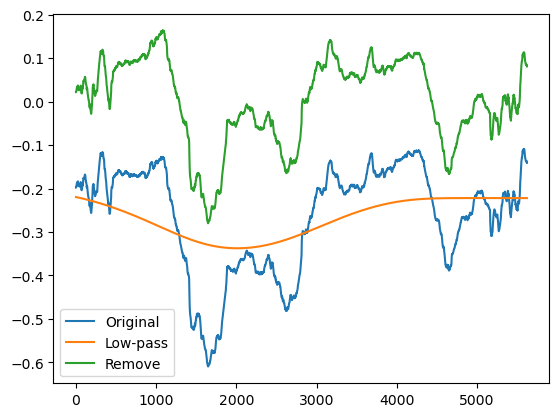

destriping


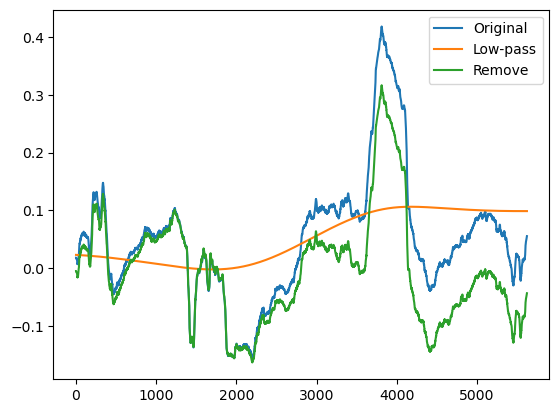

In [ ]:

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/OrthosInterpolated/mm26JUN26150940CatiaLaMar_Interpolated.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/OrthosInterpolated/mm26APR05150213CatiaLaMar_Interpolated.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/OrthosInterpolated/MEC_CatiaLaMar_to26/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/OrthosInterpolated/mm26JUN26151008_Naiguata_Interpolated.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/OrthosInterpolated/mm25DEC20145444_Naiguata_Interpolated.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/OrthosInterpolated/MEC_Naiguata/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/OrthosInterpolated/mm26JUN25142021CatiaLaMar_Interpolated.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/OrthosInterpolated/mm26APR05150213CatiaLaMar_Interpolated.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/OrthosInterpolated/MEC_CatiaLaMar_to25/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/OrthosInterpolated/mm26JUN25142021CatiaLaMar_Interpolated.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/OrthosInterpolated/mm26JUN26150940CatiaLaMar_Interpolated.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/OrthosInterpolated/MEC_CatiaLaMar_25to26/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/OrthosInterpolated/mm26JUN26151008_Carabadella_Interpolated.tif', 
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/OrthosInterpolated/mm26APR05150229_Carabadella_Interpolated.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/OrthosInterpolated/MEC_Caraballeda/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/OrthosInterpolated/mm26JUL05150537_CamuriGrande_Interpolated.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/OrthosInterpolated/mm25DEC27150737_CamuriGrande_Interpolated.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/OrthosInterpolated/MEC_CamuriGrande/'

tt.micmacPostProcessing(folder=folder,
                             prefiles=prefiles,
                             outprefix=folder)

import rasterio
files = [f'{folder}NSmicmac.tif',
         f'{folder}EWmicmac.tif']

landmask_file = '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/gshhg-shp-2.3.7/GSHHS_shp/f/GSHHS_f_L1_epsg32619.shp'

for file in files:
    with rasterio.open(file) as src:
        arr = src.read(1)
        profile = src.profile
        nodata = src.nodata
    with rasterio.open(f'{folder}Correlmicmac.tif') as csrc:
        corr = csrc.read(1)
        mask = (corr < 0.2)
        
        if file.__contains__('Naiguata'):
            print('destriping')
            if file.__contains__('EW'):
                angle = 90
            elif file.__contains__('NS'):
                angle = 0
            destriped = rotate_stripe_remove(arr, cutoff=0.001, fs=1, order=2,angle=angle,nodata=nodata)

        elif file.__contains__('Camuri'):
            print('destriping')
            angle=90
            destriped = rotate_stripe_remove(arr, cutoff=0.0002, fs=1, order=2,angle=angle,nodata=nodata)

        else:
            print('not destriping')
            destriped = arr
        
        destriped[mask] = nodata

        with rasterio.open(f"{file[:-4]}_{folder.split('/')[-2][4:]}_masked.tif", "w", **profile) as dst:
            dst.write(destriped, 1)

            files = ['/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/POSTsentinel2_band4_2026-06-24_2026-06-29-0000000000-0000000000.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/S2_GEE/PREsentinel2_band4_2026-05-05_2026-05-09-0000000000-0000000000.tif']


In [8]:
import rasterio
import geopandas as gpd

In [ ]:
# Ocean Mask
files = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_Naiguata_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_CamuriGrande_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_Caraballeda_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_CatiaLaMar_25to26_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_CatiaLaMar_to25_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/NSmicmac_CatiaLaMar_to26_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_Naiguata_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_CatiaLaMar_to26_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_CatiaLaMar_to25_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_CatiaLaMar_25to26_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_Caraballeda_masked.tif', 
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/AllDisplacementsCurrent/EWmicmac_CamuriGrande_masked.tif']

landmask_file = '/Volumes/Venezuela/Venezuela2026Doublet/GIS/OceanMask.shp'

for file in files:
    with rasterio.open(file) as src:
        arr = src.read(1)
        profile = src.profile
        nodata = src.nodata
        transform = src.transform
        crs = src.crs

    masked, _ = mask_ocean(arr,transform,crs,landmask_file,
                nodata=-9999,coastline_buffer=1)
        
    with rasterio.open(f"{file[:-4]}_ocean.tif", "w", **profile) as dst:
            dst.write(masked, 1)


## Old

In [ ]:
# NOT INTERPOLATED
gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.39 -0.39 -te 712305.75 1170530.4 722657.52 1174219.02  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/26APR05150213-P1BS-200013358610_01_P002.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26APR05150213Airport.tif
gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.39 -0.39 -te 712305.75 1170530.4 722657.52 1174219.02  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
            /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/26JUN26150940-P1BS-200013358430_01_P003.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26JUN26150940Airport.tif
gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.39 -0.39 -te 712305.75 1170530.4 722657.52 1174219.02  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
            /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/26JUN25142021-P1BS-200013376357_01_P005.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26JUN25142021Airport.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.35 -0.35 -te 733855.358 1173474.704 737073.608 1175144.204  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/Orthos/26APR05150229-P1BS-200013376013_01_P001_Carabadella.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/Orthos/mm26APR05150229Carabadella.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.35 -0.35 -te 733855.358 1173474.704 737073.608 1175144.204  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/Orthos/26JUN26151008-P1BS-200013375988_01_P003_Carabadella.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/Orthos/mm26JUN26151008Carabadella.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.35 -0.35 -te 746296.026 1174314.942 748279.832 1175557.546  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/Orthos/26JUN26151008-P1BS-200013377601_01_P003_Naiguata_modified.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/Orthos/mm26JUN26151008Naiguata.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.35 -0.35 -te 746296.026 1174314.942 748279.832 1175557.546  -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/Orthos/25DEC27150749-P1BS-200013377606_01_P002_Naiguata_modified.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/Orthos/mm25DEC27150749Naiguata.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.32 -0.32 -te 749226.8 1174974.6 751026.7 1175690.0 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/25DEC27150737-P1BS-200013384701_01_P002_Camuri_modified.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/mm25DEC27150737Camuri.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.32 -0.32 -te 749226.8 1174974.6 751026.7 1175690.0 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/26JUL05150537-P1BS-200013428293_01_P004_Camuri_modified.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/mm26JUL05150537Camuri.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.32 -0.32 -te 749226.8 1174974.6 751026.7 1175690.0 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/25DEC27150737-P1BS-200013384701_01_P002_Camuri_modified.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/mm25DEC27150737Camuri.tif

gdalwarp -t_srs EPSG:32619 -overwrite  \
          -tr 0.32 -0.32 -te 749226.8 1174974.6 751026.7 1175690.0 -r near -of GTiff -ot Float32 -dstnodata -9999 -co COMPRESS=LZW -co ZLEVEL=9 -co BIGTIFF=YES \
          /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/26JUL05150537-P1BS-200013428293_01_P004_Camuri_modified.tif /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/mm26JUL05150537Camuri.tif


In [2]:
prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26APR05150213.tif',
'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26JUN26150940.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3Airport/'


prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/Orthos/mm26APR05150229Carabadella.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/Orthos/mm26JUN26151008Carabadella.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/MEC_WV3_Caraballeda/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/Orthos/mm26JUN26151008Naiguata.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/Orthos/mm25DEC27150749Naiguata.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/MEC_WV3_Naiguata/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26JUN26150940Airport.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26JUN25142021Airport.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3Lg_Airport_25thTo26th/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26APR05150213Airport.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26JUN25142021Airport.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3Lg_Airport_25th/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26APR05150213Airport.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/mm26JUN26150940Airport.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3_Airport_26th/'

prefiles = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/mm26JUL05150537Camuri.tif',
            '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/mm25DEC27150737Camuri.tif']
folder = '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/MEC_WV3toGEO1_Camuri/'

tt.micmacPostProcessing(folder=folder,
                             prefiles=prefiles,
                             outprefix=folder)


/Users/chanagan/miniforge3/envs/ImageryResources/lib/python3.14/site-packages/osgeo/gdal.py:606: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


Nodata value for mask: -9999.0
Setting nodata value to -9999
Saving /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/MEC_WV3toGEO1_Camuri/NSmicmac.tif
Saving /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/MEC_WV3toGEO1_Camuri/EWmicmac.tif
Saving /Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/MEC_WV3toGEO1_Camuri/Correlmicmac.tif


destriping


/var/folders/cl/y9nzvjr51wjdfxvfj59yzn400000gp/T/ipykernel_95947/1609523755.py:85: RuntimeWarning: Mean of empty slice
  y = np.nanmean(rotated_data,axis=1)  # Use nanmean to ignore NoData values


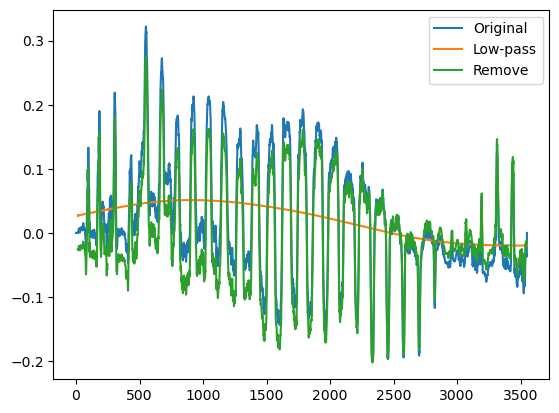

destriping


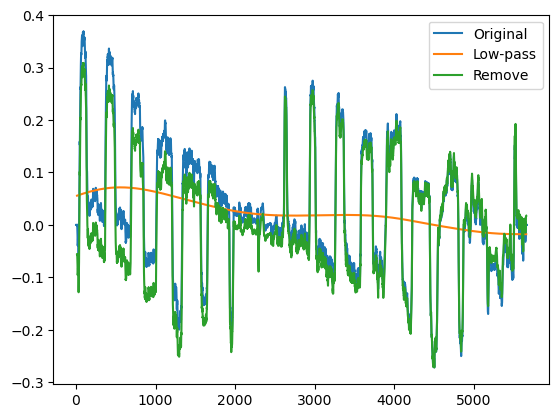

In [93]:
import rasterio
files = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/MEC_WV3_Naiguata/NSmicmac.tif',
         '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Naiguata/MEC_WV3_Naiguata/EWmicmac.tif']

#files = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3Lg_Airport_25thTo26th/NSmicmac.tif', 
#'/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3Lg_Airport_25thTo26th/EWmicmac.tif']

#files = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3Lg_Airport_25th/EWmicmac.tif',
#         '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3Lg_Airport_25th/NSmicmac.tif']

#files = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3_Airport_26th/NSmicmac.tif',
#         '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Orthos/MEC_WV3_Airport_26th/EWmicmac.tif']

#files = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/MEC_WV3toGEO1_Camuri/EWmicmac.tif',
#         '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Camuri/orthos/MEC_WV3toGEO1_Camuri/NSmicmac.tif']

#files = ['/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/MEC_WV3_Caraballeda/EWmicmac.tif',
#         '/Volumes/Venezuela/Venezuela2026Doublet/WorldViewBasic/Caraballeda/MEC_WV3_Caraballeda/NSmicmac.tif']

for file in files:
    with rasterio.open(file) as src:
        arr = src.read(1)
        profile = src.profile
        nodata = src.nodata
        
        if file.__contains__('Camuri') or file.__contains__('Naiguata'):
            print('destriping')
            if file.__contains__('EW'):
                angle = 90
            elif file.__contains__('NS'):
                angle = 0
            destriped = rotate_stripe_remove(arr, cutoff=0.0003, fs=1, order=2,angle=angle,nodata=nodata)

        else:
            print('not destriping')
            destriped = arr
        
        buffered = buffer_nodata(destriped, nodata=nodata, buffer_pixels=8)

        with rasterio.open(f"{file[:-4]}_buffered.tif", "w", **profile) as dst:
            dst.write(buffered, 1)

In [5]:
destriped

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(3550, 5668))